In [16]:
import polars as pl
import matplotlib.pyplot as plt

In [17]:
# 1.

columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

df = pl.read_csv(
    "../datasets/renda_adulta.csv",
    has_header=False,
    new_columns=columns,
    null_values=["?"]
)

In [18]:
# 2.

df.schema

Schema([('age', Int64),
        ('workclass', String),
        ('fnlwgt', Int64),
        ('education', String),
        ('education-num', Int64),
        ('marital-status', String),
        ('occupation', String),
        ('relationship', String),
        ('race', String),
        ('sex', String),
        ('capital-gain', Int64),
        ('capital-loss', Int64),
        ('hours-per-week', Int64),
        ('native-country', String),
        ('income', String)])

In [19]:
# 3.

df.shape

(32561, 15)

In [20]:
# 4.

df["income"].value_counts()

income,count
str,u32
""">50K""",7841
"""<=50K""",24720


In [21]:
# 5.

cut = df[["capital-gain", "capital-loss"]]

renda_longo = cut.unpivot(on=["capital-gain", "capital-loss"], variable_name="tipo", value_name="Valor")
renda_longo

tipo,Valor
str,i64
"""capital-gain""",2174
"""capital-gain""",0
"""capital-gain""",0
"""capital-gain""",0
"""capital-gain""",0
…,…
"""capital-loss""",0
"""capital-loss""",0
"""capital-loss""",0


In [22]:
# 6.

time_income = df.group_by("income").agg(pl.col("hours-per-week").mean().alias("media_horas"))
time_income

income,media_horas
str,f64
""">50K""",45.473026
"""<=50K""",38.84021


In [23]:
# 7.

df["occupation"].value_counts()

occupation,count
str,u32
"""Farming-fishing""",994
"""Adm-clerical""",3770
"""Tech-support""",928
"""Other-service""",3295
"""Protective-serv""",649
…,…
"""Craft-repair""",4099
null,1843
"""Armed-Forces""",9


<BarContainer object of 2 artists>

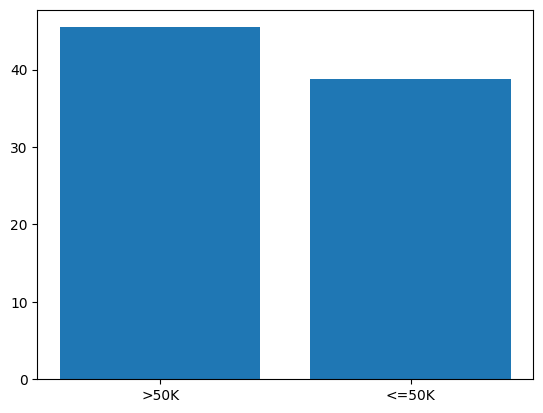

In [24]:
# 8.

plt.bar(time_income["income"], time_income["media_horas"])